## Black-Scholes and the Greeks


Pricing options and reading their risk with the framework that gave the market its common language.

<br>


<p style="margin-bottom:-8px"><b>Key Highlights:</b></p>

- **Black-Scholes-Merton (BSM)** turns five inputs into one fair price and valuable risk sensitivities.
- Its central idea is **replication**: synthesizing an option from stock and cash ties its price directly to replication cost.
- Hence, the stock's **expected return drops out** of the equation — 2 investors who disagree on direction must still agree on the price.
- The **Greeks** (Delta $\Delta$, Gamma $\Gamma$, Vega $\nu$, Theta $\Theta$, Rho $\rho$) measure sensitivity to underlying price, convexity, volatility, time decay, and interest rates, respectively.
- Options are still *quoted* in Black-Scholes implied volatility, even where the model's assumptions fail.

<br>

[*Content format: Tutorial (T) · Category: Quant Foundations & Derivatives (1)*   =====================> insert project card]

<br>


<p style="margin-bottom:-8px"><b>Table of Content:</b></p>

<ol>
  <li><span style="display:inline-block;width:180px"><b>Introduction</b></span>(Black-Scholes in a nutshell)</li>
  <li><span style="display:inline-block;width:180px"><b>Intuition</b></span>(why replication removes the need to forecast)</li>
  <li><span style="display:inline-block;width:180px"><b>Theory</b></span>(the formula, the Greeks, and put-call parity)</li>
  <li><span style="display:inline-block;width:180px"><b>Application</b></span>(price and risk a 3-month QQQ option)</li>
  <li><span style="display:inline-block;width:180px"><b>Conclusion</b></span>(strengths, limitations, and where to go next)</li>
</ol>

In [1]:
# Setup

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

np.random.seed(42)  # reproducibility (standard arbitrary number)
plt.rcParams["figure.dpi"] = 110

# ---- house style ---------------------------------------------------------
BG    = "#F4F2E8"   # Pale Sisal
INK   = "#151515"   # Anthracite
AQUA  = "#1FFFFF"   # accent
GREY  = "#7A7A7A"

HEAD  = {"fontname": "Switzer", "fontsize": 11, "fontweight": "bold", "color": INK}
SUB   = {"fontname": "Switzer", "fontsize": 9,  "fontweight": "bold", "color": INK}

plt.rcParams.update({
    "font.family": "monospace",
    "font.monospace": ["Courier Prime", "Courier New", "DejaVu Sans Mono"],
    "font.size": 8,
    "axes.titlesize": 11, "axes.labelsize": 8,
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "axes.edgecolor": GREY, "axes.labelcolor": GREY,
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "grid.color": "#CCCCCC", "grid.linewidth": 0.5,
    "legend.frameon": False,
    "lines.linewidth": 2.0, "lines.markersize": 0,
})

### 1. Introduction

A few simple facts to get up to speed:

- Black-Scholes maps **five inputs** — spot, strike, time to expiration, interest rate, volatility — onto a single arbitrage-free price.

- The option is **replicable**: hold $\Delta$ shares against it and rebalance continuously, and you manufacture its payoff from stock and cash.

- Because replication pins the price, the stock's **expected return $\mu$ never appears** (drift independence) — only volatility matters.

- **4 of the 5 inputs are observable** — volatility is not:  
– that single unknown is what the option premium is really quoting  
– inverting the formula on a market price gives the **implied volatility**

### 2. Intuition

The logic before diving into equations:

- **Replication, not prediction**<br>
– Selling a call and holding $\Delta$ shares against it creates a delta-neutral position that momentarily eliminates directional risk.<br>
– Continuous rebalancing reproduces the option's payoff strictly from stock and cash alone.<br>
– No-arbitrage conditions are the basis for the price (fair value) irrespective of bias: bulls and bears quote the same number.

- **Volatility is the price of uncertainty**<br>
– Options feature non-linear, asymmetric payoffs (convexity): a wider distribution (higher $\sigma$) means a higher probability of in-the-money outcomes.<br>
– Higher $\sigma$ therefore lifts **both** calls and puts.<br>
– Future volatility is unobservable, hence market pricing reflects differing expectations of $\sigma$.

- **The Greeks are a risk dashboard**<br>
– Traders rarely ask "what is the price?" — they ask "what happens to my book if spot drops 1%, vol jumps 2 points, and a day passes?"<br>
– Each Greek answers one of those questions, one partial derivative at a time.<br>
– $\Delta$ is the hedge ratio, $\Gamma$ the cost of keeping it, $\nu$ the vol exposure, $\Theta$ the rent you pay for time.

### 3. Theory

Below the theoretical foundation and respective equations:

- **The pricing formula**  
– $N(d_2)$ reads as the risk-neutral probability of finishing in the money; $N(d_1)$ is the call's delta.  
$d_1 = \dfrac{\ln(S/K) + (r + \tfrac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$  
$C = S\,N(d_1) - K e^{-rT} N(d_2), \qquad P = K e^{-rT} N(-d_2) - S\,N(-d_1)$

- **The Greeks in closed form**  
– Each is a partial derivative of the price with respect to one input.  
$\Delta_C = N(d_1), \qquad \Gamma = \dfrac{N'(d_1)}{S\sigma\sqrt{T}}, \qquad \nu = S\,N'(d_1)\sqrt{T}$  
$\Theta_C = -\dfrac{S N'(d_1)\sigma}{2\sqrt{T}} - rKe^{-rT}N(d_2), \qquad \rho_C = K T e^{-rT} N(d_2)$

- **Put-call parity — the free sanity check**  
– Holds by arbitrage alone, independent of any model: if your implementation violates it, the bug is yours.  
$C - P = S - K e^{-rT}$

The two functions below implement this: one returns the **price**, the other the full **Greek** set.

In [2]:
# Implementation

def bs_price(S, K, T, r, sigma, kind="call"):
    """Black-Scholes price of a European call or put."""
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    if kind == "call":
        return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    return K * np.exp(-r * T) * norm.cdf(-d2) - S * norm.cdf(-d1)

def bs_greeks(S, K, T, r, sigma, kind="call"):
    """Delta, Gamma, Vega, Theta (per year) and Rho of a European option."""
    d1 = (np.log(S / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    s  = 1 if kind == "call" else -1
    return {
        "delta": s * norm.cdf(s * d1),
        "gamma": norm.pdf(d1) / (S * sigma * np.sqrt(T)),
        "vega":  S * norm.pdf(d1) * np.sqrt(T),
        "theta": (-S * norm.pdf(d1) * sigma / (2 * np.sqrt(T))
                  - s * r * K * np.exp(-r * T) * norm.cdf(s * d2)),
        "rho":   s * K * T * np.exp(-r * T) * norm.cdf(s * d2),
    }

### 4. Application

**Set the inputs from real data**  
- We pull daily QQQ prices and use trailing 1-year realised volatility of log returns as the $\sigma$ input.  
- In practice a trader would use the *implied* vol quoted in the market.

In [3]:
TICKER = "QQQ"
START, END = "2018-01-01", "2024-12-31"

import yfinance as yf

px = (yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)["Close"]
        .squeeze().rename(TICKER).dropna())

log_ret = np.log(px / px.shift(1)).dropna()

S0    = float(px.iloc[-1])
SIGMA = float(log_ret.tail(252).std() * np.sqrt(252))   # trailing 1y realised vol
R     = 0.045                                           # short-term risk-free rate
T3M   = 0.25                                            # 3 months
K_ATM = round(S0)                                       # at-the-money strike

call = bs_price(S0, K_ATM, T3M, R, SIGMA, "call")
put  = bs_price(S0, K_ATM, T3M, R, SIGMA, "put")
g    = bs_greeks(S0, K_ATM, T3M, R, SIGMA, "call")

print(f"{TICKER}: spot = {S0:,.2f}   sigma = {SIGMA:.2%}   r = {R:.2%}")
print(f"3M ATM call (K={K_ATM}): {call:7.2f}")
print(f"3M ATM put  (K={K_ATM}): {put:7.2f}\n")
print("3M ATM call Greeks:")
print(f"  delta {g['delta']:7.3f}   gamma {g['gamma']:8.5f}   vega {g['vega']:7.2f}"
      f"   theta {g['theta']/365:7.3f}/day   rho {g['rho']:6.2f}")

QQQ: spot = 511.27   sigma = 18.02%   r = 4.50%
3M ATM call (K=511):   21.41
3M ATM put  (K=511):   15.43

3M ATM call Greeks:
  delta   0.570   gamma  0.00853   vega  100.42   theta  -0.132/day   rho  67.47


- **The Greeks across strikes** — where the risk actually sits  
– **Delta** rolls from 0 to 1 like a smoothed step: deep OTM behaves like nothing, deep ITM like the stock itself.  
– **Gamma and Vega peak at the money** — that is where hedges churn fastest and vol exposure is largest.  
– **Theta is most negative at the money too**: the option with the most optionality has the most to lose from a day passing.

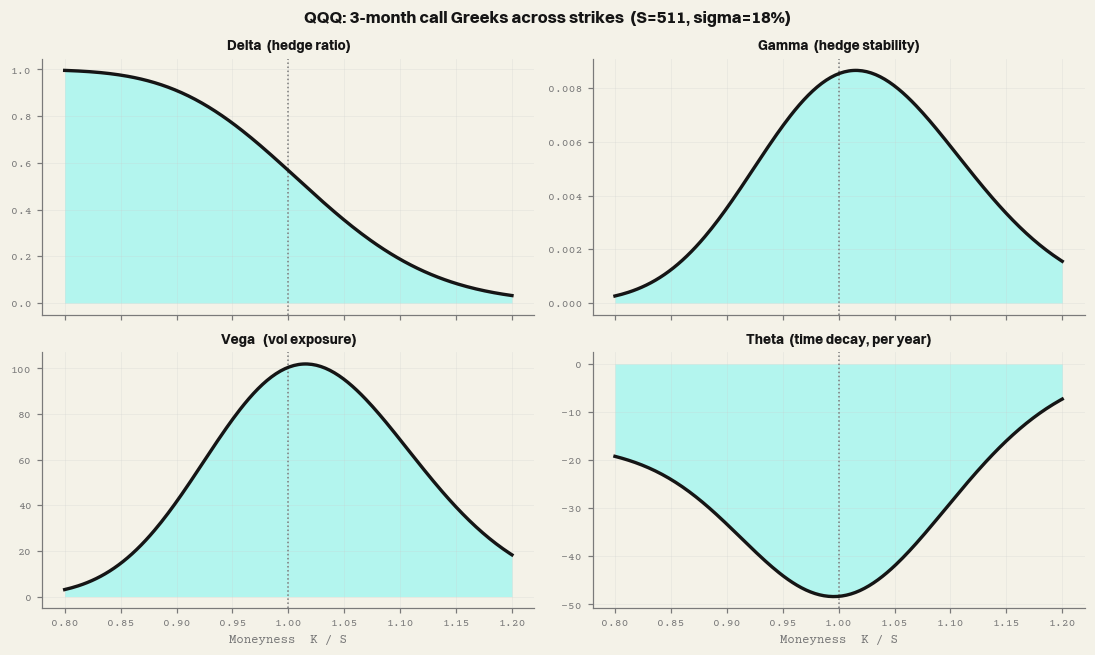

In [4]:
strikes = np.linspace(0.80 * S0, 1.20 * S0, 200)
moneyness = strikes / S0

G = {k: [] for k in ["delta", "gamma", "vega", "theta"]}
for K in strikes:
    gk = bs_greeks(S0, K, T3M, R, SIGMA, "call")
    for k in G:
        G[k].append(gk[k])

LABEL = {"delta": "Delta  (hedge ratio)",
         "gamma": "Gamma  (hedge stability)",
         "vega":  "Vega   (vol exposure)",
         "theta": "Theta  (time decay, per year)"}

fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, k in zip(axes.flat, ["delta", "gamma", "vega", "theta"]):
    ax.plot(moneyness, G[k], color=INK, lw=2.2, zorder=3)
    ax.fill_between(moneyness, G[k], 0, color=AQUA, alpha=0.30, lw=0, zorder=1)
    ax.axvline(1.0, color=GREY, lw=1.0, ls=":", zorder=2)
    ax.set_title(LABEL[k], **SUB)
for ax in axes[1]:
    ax.set_xlabel("Moneyness  K / S")

fig.suptitle(f"{TICKER}: 3-month call Greeks across strikes  "
             f"(S={S0:,.0f}, sigma={SIGMA:.0%})", **HEAD)
plt.tight_layout(); plt.show()

- **Time decay** — the option's ticking clock  
– Repricing the same option as expiry approaches isolates $\Theta$: value bleeds away slowly at first, then **accelerates sharply in the final weeks**.  
– At the money the decay is roughly proportional to $\sqrt{T}$, so the last month costs far more than the first.  
– This asymmetry is the entire economics of short-dated option selling — and of 0DTE trading.

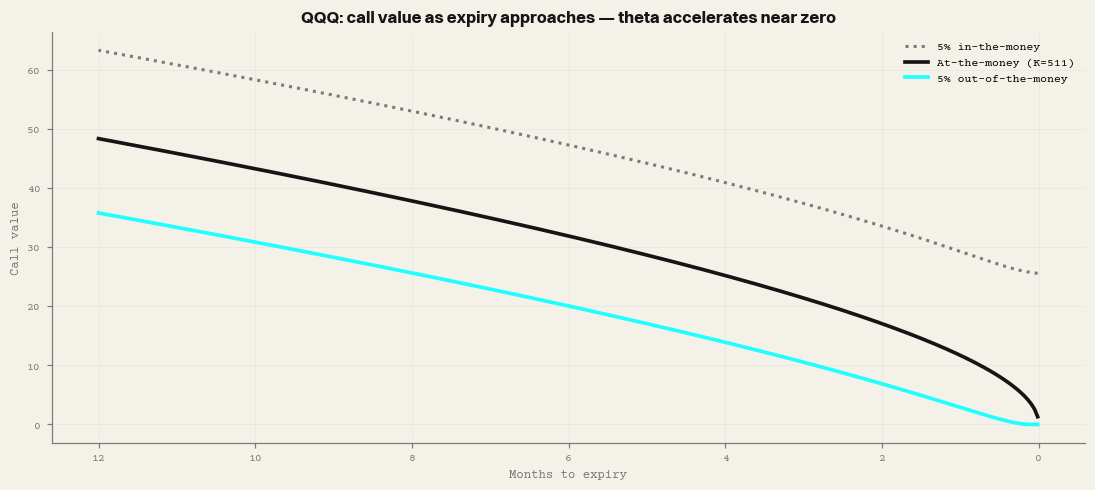

In [5]:
maturities = np.linspace(1e-3, 1.0, 300)
atm = [bs_price(S0, K_ATM,      t, R, SIGMA, "call") for t in maturities]
otm = [bs_price(S0, 1.05 * S0,  t, R, SIGMA, "call") for t in maturities]
itm = [bs_price(S0, 0.95 * S0,  t, R, SIGMA, "call") for t in maturities]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(maturities * 12, itm, color=GREY,  lw=2.0, ls=":",  label="5% in-the-money")
ax.plot(maturities * 12, atm, color=INK,   lw=2.4,          label=f"At-the-money (K={K_ATM})")
ax.plot(maturities * 12, otm, color=AQUA,  lw=2.4,          label="5% out-of-the-money")
ax.set_title(f"{TICKER}: call value as expiry approaches — theta accelerates near zero", **HEAD)
ax.set_xlabel("Months to expiry"); ax.set_ylabel("Call value")
ax.invert_xaxis(); ax.legend()
plt.tight_layout(); plt.show()

- **Sanity checks:** parity and Monte Carlo  
– **Put-call parity** is model-free, so it must hold to machine precision: any visible error is an implementation bug, not a modelling choice.  
– **Monte Carlo under risk-neutral GBM** must converge to the closed form — Black-Scholes *is* the discounted expected payoff of the GBM from Tutorial 1, with the drift set to $r$.  
– **How to read the result:** the simulated price carries standard error $\approx \text{sd}(\text{payoff})/\sqrt{N}$; landing within ~2 SE is agreement, a gap that persists as $N$ grows is a bug.

In [6]:
# 1) put-call parity: C - P = S - K e^{-rT}
lhs, rhs = call - put, S0 - K_ATM * np.exp(-R * T3M)
print(f"parity:  C - P = {lhs:10.6f}   S - Ke^-rT = {rhs:10.6f}   diff = {abs(lhs - rhs):.2e}")

# 2) Monte Carlo under risk-neutral GBM (drift = r)
N   = 200_000
z   = np.random.normal(size=N)
S_T = S0 * np.exp((R - 0.5 * SIGMA**2) * T3M + SIGMA * np.sqrt(T3M) * z)
payoff  = np.maximum(S_T - K_ATM, 0)
mc_call = np.exp(-R * T3M) * payoff.mean()
se      = np.exp(-R * T3M) * payoff.std() / np.sqrt(N)

print(f"Monte Carlo call: {mc_call:.3f} +/- {2*se:.3f} (2 SE)   closed form: {call:.3f}")
print(f"gap = {abs(mc_call - call)/se:.2f} standard errors")

parity:  C - P =   5.983532   S - Ke^-rT =   5.983532   diff = 5.68e-14
Monte Carlo call: 21.435 +/- 0.136 (2 SE)   closed form: 21.409
gap = 0.38 standard errors


### 5. Conclusion

<p style="font-size:1.15em; font-weight:600; margin-bottom:-10px">Strengths</p>

- **Closed form** — instant prices and Greeks, no simulation required
- **Preference-free** — the stock's expected return drops out; only volatility matters
- **The market's common language** — options are quoted in BS implied vol even where its assumptions fail
- **Analytic Greeks** — the entire hedging and risk-reporting industry runs on them

<p style="font-size:1.15em; font-weight:600; margin-bottom:-10px">Weaknesses & Limitations</p>

- **Constant volatility** — the market trades a smile/skew; one number cannot price every strike
- **GBM underlying** — no jumps and thin tails, so deep out-of-the-money puts are systematically underpriced
- **European exercise only** — American early exercise needs trees or numerical methods
- **Frictionless continuous hedging** — real rebalancing is discrete and costs money

<p style="font-size:1.15em; font-weight:600; margin-bottom:-10px">Applications in Practice</p>

- Pricing and hedging European options and warrants
- Extracting implied volatility — the quoting convention of the entire options market
- Real-time Greek dashboards for market-making and portfolio risk

<p style="font-size:1.15em; font-weight:600; margin-bottom:-10px">Alternatives & Extensions</p>

- **Stochastic volatility** — Heston, which bends to fit the smile
- **Jump-diffusion** — Merton, for crash risk and steep short-dated skew
- **Local volatility** — Dupire, fitting the entire observed surface
- **Binomial trees** — American exercise, discrete dividends, path dependence